# Model B - Lightweight CNN (Depthwise Separable Convolutions)

Fixed version: BatchNorm + He init + standardized inputs so that Adam, SGD and SGD with Momentum all converge.

Check Dataset

In [1]:
from pathlib import Path
from collections import Counter
from PIL import Image
import numpy as np
import os

# Dataset path (notebook is run from the Model_B folder)
DATASET_PATH = Path("../split")
print("Working dir :", os.getcwd())
print("Dataset path:", DATASET_PATH.resolve())

for split in ["train", "validation", "test"]:
    files = sorted((DATASET_PATH / split).glob("*.pgm"))
    print(f"{split}: {len(files)} images")
    for f in files[:3]:
        img = Image.open(f)
        print("   ", f.name, "->", img.size, img.mode)

Working dir : d:\UOM\Sem 5\Pattern\Assignment03\RocogniX_Classification_Assignment\Model_B
Dataset path: D:\UOM\Sem 5\Pattern\Assignment03\RocogniX_Classification_Assignment\split
train: 436 images
    an2i_left_happy_open_2.pgm -> (64, 60) L
    an2i_left_happy_sunglasses_2.pgm -> (64, 60) L
    an2i_left_neutral_open_2.pgm -> (64, 60) L
validation: 93 images
    an2i_left_angry_open_2.pgm -> (64, 60) L
    an2i_left_angry_sunglasses_2.pgm -> (64, 60) L
    an2i_right_angry_sunglasses_2.pgm -> (64, 60) L
test: 95 images
    an2i_left_sad_open_2.pgm -> (64, 60) L
    an2i_up_angry_sunglasses_2.pgm -> (64, 60) L
    an2i_up_happy_sunglasses_2.pgm -> (64, 60) L


In [2]:
# Class distribution per split
poses = ["straight", "left", "right", "up"]

for split in ["train", "validation", "test"]:
    files = list((DATASET_PATH / split).glob("*.pgm"))
    counts = Counter(f.stem.split("_")[1] for f in files)
    print(f"{split}:")
    for pose in poses:
        print(f"   {pose:8s}: {counts[pose]}")

train:
   straight: 109
   left    : 105
   right   : 113
   up      : 109
validation:
   straight: 26
   left    : 25
   right   : 23
   up      : 19
test:
   straight: 21
   left    : 27
   right   : 19
   up      : 28


Load Dataset into NumPy

In [3]:
CLASS_TO_INDEX = {"straight": 0, "left": 1, "right": 2, "up": 3}
CLASS_NAMES = list(CLASS_TO_INDEX.keys())

def load_dataset(split):
    folder = DATASET_PATH / split
    images, labels = [], []

    for file in sorted(folder.glob("*.pgm")):
        # filename: userid_pose_expression_eyes_scale.pgm
        pose = file.stem.split("_")[1]
        label = CLASS_TO_INDEX[pose]

        image = np.array(Image.open(file), dtype=np.float32) / 255.0   # 0-255 -> 0-1
        image = np.expand_dims(image, axis=-1)                          # (60,64) -> (60,64,1)

        images.append(image)
        labels.append(label)

    return np.array(images, dtype=np.float32), np.array(labels, dtype=np.int64)

X_train, y_train = load_dataset("train")
X_val, y_val = load_dataset("validation")
X_test, y_test = load_dataset("test")

print("X_train:", X_train.shape, "y_train:", y_train.shape)
print("X_val:  ", X_val.shape,   "y_val:  ", y_val.shape)
print("X_test: ", X_test.shape,  "y_test: ", y_test.shape)
print("Pixel range:", X_train.min(), "to", X_train.max())
print("Classes:", CLASS_TO_INDEX)

X_train: (436, 60, 64, 1) y_train: (436,)
X_val:   (93, 60, 64, 1) y_val:   (93,)
X_test:  (95, 60, 64, 1) y_test:  (95,)
Pixel range: 0.0 to 0.9882353
Classes: {'straight': 0, 'left': 1, 'right': 2, 'up': 3}


Visualise the loaded data

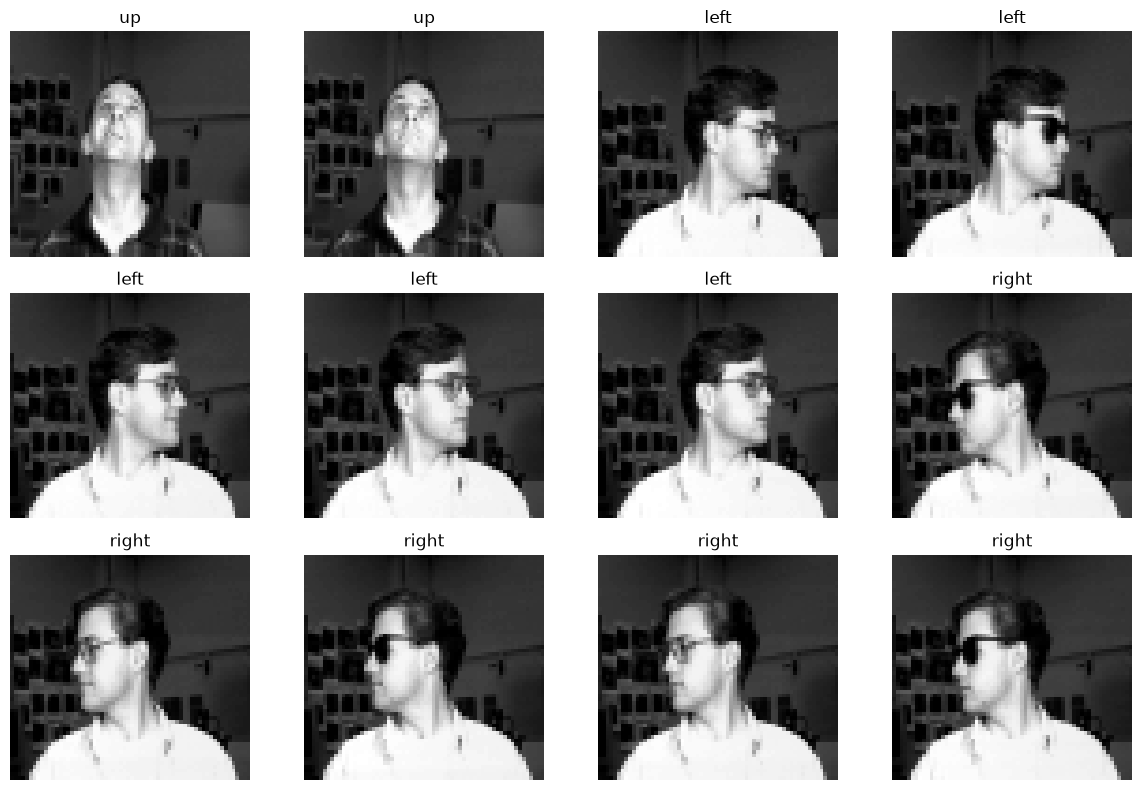

In [4]:
import matplotlib.pyplot as plt

num_images = 12
start_image_index = 60

plt.figure(figsize=(12, 8))
for i in range(num_images):
    plt.subplot(3, 4, i + 1)
    plt.imshow(X_train[i + start_image_index].squeeze(), cmap="gray")
    plt.title(CLASS_NAMES[y_train[i + start_image_index]])
    plt.axis("off")
plt.tight_layout()
plt.show()

Standardize inputs (FIX 1)

Inputs in [0, 1] are not zero-centred. SGD is far more sensitive to this than Adam, so we standardize using **training-set statistics only** and apply the same transform to validation and test data.

In [5]:
mean, std = X_train.mean(), X_train.std()
print(f"Train mean={mean:.4f}, std={std:.4f}")

X_train_n = (X_train - mean) / std
X_val_n   = (X_val   - mean) / std
X_test_n  = (X_test  - mean) / std

print("Normalised train mean/std:", X_train_n.mean().round(4), X_train_n.std().round(4))

Train mean=0.2753, std=0.2529
Normalised train mean/std: 0.0 1.0


Model B Implementation (FIX 2 and 3)

Why SGD failed before: no normalization + depthwise convs with fan-in of only 9 + global average pooling made the gradients vanishingly small. Adam rescales each gradient so it still escapes, plain SGD (`lr x grad`) does not.

Fixes: **BatchNorm** after every conv (keeps activation/gradient scale stable, and folds into the conv at inference so it is free on edge hardware) and **He initialisation** (suited to ReLU).

In [6]:
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.optimizers import Adam, SGD

def sep_block(filters, pool=True):
    block = [
        layers.SeparableConv2D(
            filters, 3, padding="same", use_bias=False,        # BN supplies the bias/shift
            depthwise_initializer="he_normal",
            pointwise_initializer="he_normal"),
        layers.BatchNormalization(),
        layers.ReLU(),
    ]
    if pool:
        block.append(layers.MaxPooling2D(2))
    return block

def build_model_B():
    return models.Sequential([
        layers.Input(shape=(60, 64, 1)),

        *sep_block(32),
        *sep_block(64),
        *sep_block(128),
        *sep_block(192, pool=False),

        layers.GlobalAveragePooling2D(),

        layers.Dense(128, activation="relu", kernel_initializer="he_normal"),
        layers.Dropout(0.3),
        layers.Dense(4, activation="softmax"),
    ])

tf.keras.utils.set_random_seed(42)
model_B = build_model_B()
model_B.summary()

trainable = int(sum(np.prod(w.shape) for w in model_B.trainable_weights))
print("Trainable parameters:", trainable, "(limit: 100,000)")
assert trainable <= 100_000

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ separable_conv2d                │ (None, 60, 64, 32)     │            41 │
│ (SeparableConv2D)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 60, 64, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu (ReLU)                    │ (None, 60, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 30, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ separable_conv2d_1              │ (None, 30, 32, 64)     │         2,336 │
│ (SeparableConv2D)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 30, 32, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_1 (ReLU)                  │ (None, 30, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 15, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ separable_conv2d_2              │ (None, 15, 16, 128)    │         8,768 │
│ (SeparableConv2D)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 15, 16, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_2 (ReLU)                  │ (None, 15, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 7, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ separable_conv2d_3              │ (None, 7, 8, 192)      │        25,728 │
│ (SeparableConv2D)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 7, 8, 192)      │           768 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_3 (ReLU)                  │ (None, 7, 8, 192)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 192)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        24,704 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │           516 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 63,757 (249.05 KB)

 Trainable params: 62,925 (245.80 KB)

 Non-trainable params: 832 (3.25 KB)

Trainable parameters: 62925 (limit: 100,000)


Train with Adam, SGD and SGD with Momentum

All three start from **identical initial weights** so the comparison is fair.

- Adam: lr = 0.001
- SGD: lr = 0.05
- SGD + Momentum: lr = 0.01, momentum = 0.9 (momentum multiplies the effective step by ~1/(1-0.9) = 10, so a smaller lr keeps it comparable)

If SGD+Momentum looks unstable, lower its lr to 0.005. If plain SGD is slow, try 0.1.

In [7]:
import time
from tensorflow.keras.callbacks import Callback

class EpochTimer(Callback):
    """Records how long each epoch takes."""
    def on_train_begin(self, logs=None):
        self.times = []
    def on_epoch_begin(self, epoch, logs=None):
        self.start = time.perf_counter()
    def on_epoch_end(self, epoch, logs=None):
        self.times.append(time.perf_counter() - self.start)

EPOCHS = 50
BATCH_SIZE = 32

tf.keras.utils.set_random_seed(42)
init_weights = build_model_B().get_weights()

optimizer_makers = {
    "Adam":           lambda: Adam(learning_rate=1e-3),
    "SGD":            lambda: SGD(learning_rate=0.05),
    "SGD + Momentum": lambda: SGD(learning_rate=0.01, momentum=0.9),
}

trained_models = {}
histories = {}
timers = {}

for name, make_opt in optimizer_makers.items():
    m = build_model_B()
    m.set_weights(init_weights)
    m.compile(optimizer=make_opt(),
              loss="sparse_categorical_crossentropy",
              metrics=["accuracy"])

    print(f"=== Training with {name} ===")
    timer = EpochTimer()
    h = m.fit(X_train_n, y_train,
              validation_data=(X_val_n, y_val),
              epochs=EPOCHS, batch_size=BATCH_SIZE,
              callbacks=[timer], verbose=0)
    timers[name] = timer

    trained_models[name] = m
    histories[name] = h
    print(f"  avg time per epoch: {np.mean(timer.times[1:]):.3f} s (epoch 1 skipped)")
    print(f"  final train loss {h.history['loss'][-1]:.4f} | "
          f"final val loss {h.history['val_loss'][-1]:.4f} | "
          f"final val acc {h.history['val_accuracy'][-1]:.4f}")

# The Adam model is the main Model B
model_B = trained_models["Adam"]
history_B = histories["Adam"]

=== Training with Adam ===
  avg time per epoch: 1.044 s (epoch 1 skipped)
  final train loss 0.0008 | final val loss 0.0667 | final val acc 0.9570
=== Training with SGD ===
  avg time per epoch: 1.024 s (epoch 1 skipped)
  final train loss 0.0125 | final val loss 0.0845 | final val acc 0.9892
=== Training with SGD + Momentum ===
  avg time per epoch: 0.887 s (epoch 1 skipped)
  final train loss 0.0036 | final val loss 0.0492 | final val acc 0.9892


Model B (Adam) performance plots

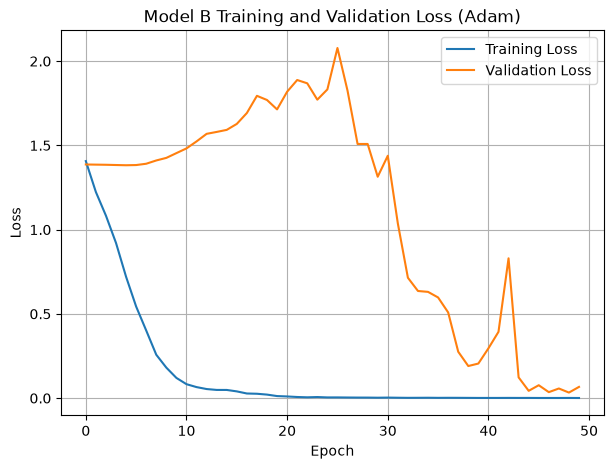

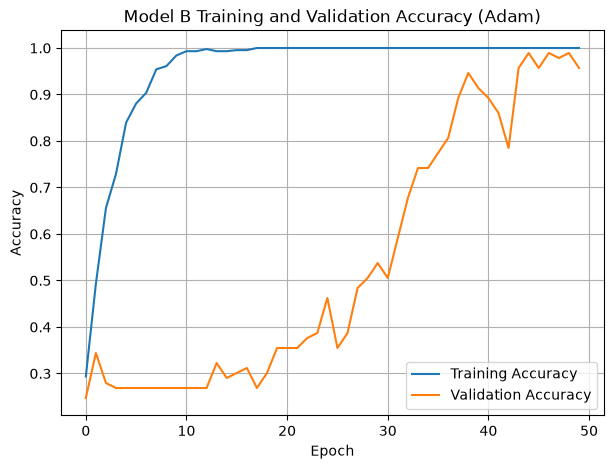

In [8]:
plt.figure(figsize=(7, 5))
plt.plot(history_B.history["loss"], label="Training Loss")
plt.plot(history_B.history["val_loss"], label="Validation Loss")
plt.xlabel("Epoch"); plt.ylabel("Loss")
plt.title("Model B Training and Validation Loss (Adam)")
plt.legend(); plt.grid(); plt.show()

plt.figure(figsize=(7, 5))
plt.plot(history_B.history["accuracy"], label="Training Accuracy")
plt.plot(history_B.history["val_accuracy"], label="Validation Accuracy")
plt.xlabel("Epoch"); plt.ylabel("Accuracy")
plt.title("Model B Training and Validation Accuracy (Adam)")
plt.legend(); plt.grid(); plt.show()

Evaluate Model B on the test set

Test Loss: 0.2109
Test Accuracy: 94.74%


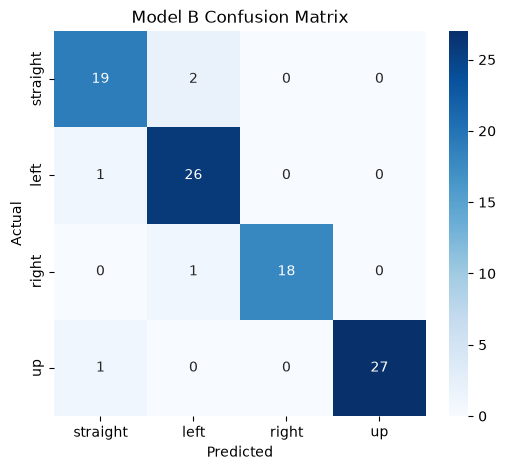

              precision    recall  f1-score   support

    straight     0.9048    0.9048    0.9048        21
        left     0.8966    0.9630    0.9286        27
       right     1.0000    0.9474    0.9730        19
          up     1.0000    0.9643    0.9818        28

    accuracy                         0.9474        95
   macro avg     0.9503    0.9448    0.9470        95
weighted avg     0.9495    0.9474    0.9479        95



In [9]:
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns

test_loss, test_accuracy = model_B.evaluate(X_test_n, y_test, verbose=0)
print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy*100:.2f}%")

y_pred = np.argmax(model_B.predict(X_test_n, verbose=0), axis=1)

cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
plt.xlabel("Predicted"); plt.ylabel("Actual")
plt.title("Model B Confusion Matrix")
plt.show()

print(classification_report(y_test, y_pred, target_names=CLASS_NAMES, digits=4))

Comparison: Adam vs SGD vs SGD with Momentum

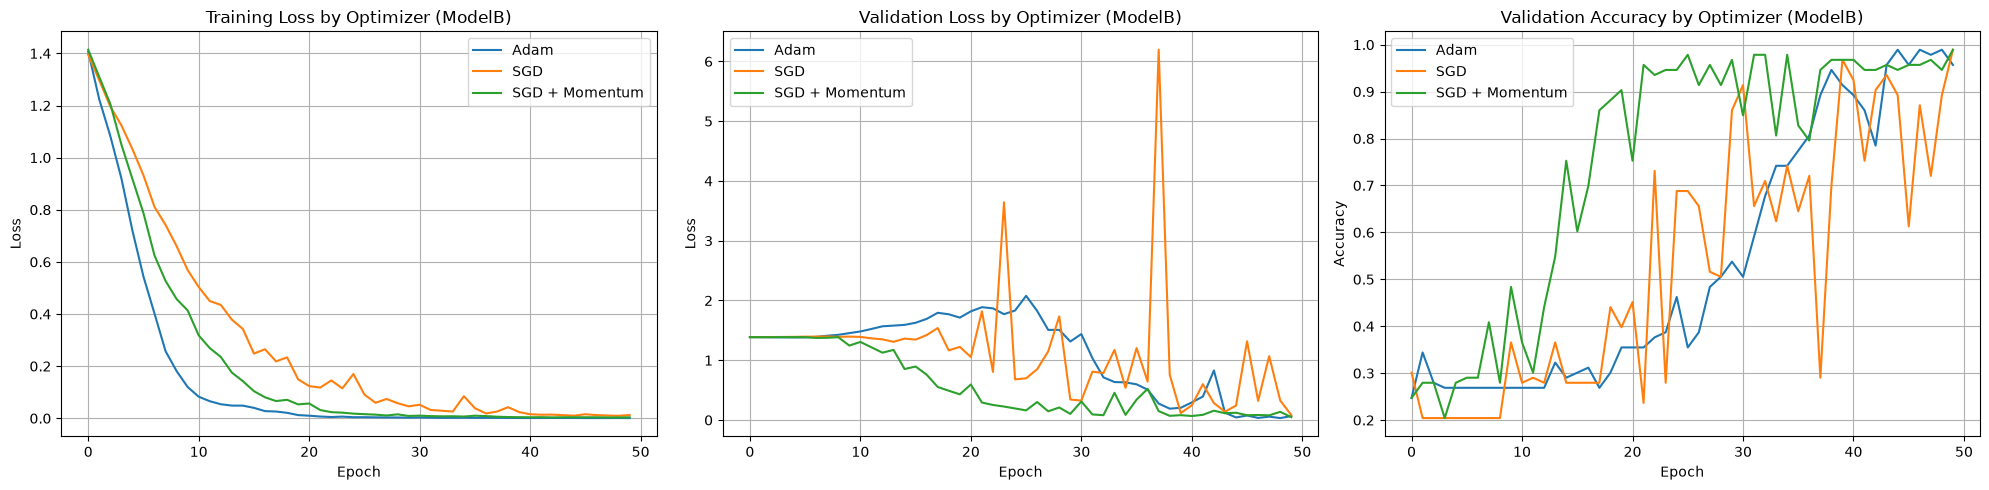

Optimizer           Best val acc  Final val loss    Test acc   Test loss
Adam                      0.9892          0.0667      0.9474      0.2109
SGD                       0.9892          0.0845      0.8947      0.2685
SGD + Momentum            0.9892          0.0492      0.9474      0.2233


In [12]:
fig, axes = plt.subplots(1, 3, figsize=(20, 5))

for name, h in histories.items():
    axes[0].plot(h.history["loss"], label=name)
    axes[1].plot(h.history["val_loss"], label=name)
    axes[2].plot(h.history["val_accuracy"], label=name)

axes[0].set_title("Training Loss by Optimizer (ModelB)")
axes[1].set_title("Validation Loss by Optimizer (ModelB)")
axes[2].set_title("Validation Accuracy by Optimizer (ModelB)")
for ax, ylabel in zip(axes, ["Loss", "Loss", "Accuracy"]):
    ax.set_xlabel("Epoch"); ax.set_ylabel(ylabel)
    ax.legend(); ax.grid(True)

plt.tight_layout()
plt.show()

# Summary table (test set)
print(f"{'Optimizer':<18}{'Best val acc':>14}{'Final val loss':>16}{'Test acc':>12}{'Test loss':>12}")
for name, m in trained_models.items():
    h = histories[name].history
    t_loss, t_acc = m.evaluate(X_test_n, y_test, verbose=0)
    print(f"{name:<18}{max(h['val_accuracy']):>14.4f}{h['val_loss'][-1]:>16.4f}{t_acc:>12.4f}{t_loss:>12.4f}")

Save Model B

In [11]:
model_B.save("model_B.keras")
np.savez("model_B_norm_stats.npz", mean=mean, std=std)   # needed to preprocess new images
print("Saved model_B.keras and normalization stats")
# ---- Numbers for the report (Model B = Adam run) ----
import os
size_kb_B = os.path.getsize("model_B.keras") / 1024
time_per_epoch_B = np.mean(timers["Adam"].times[1:])
print(f"Model B size on disk: {size_kb_B:.1f} KB")
print(f"Model B average time per epoch (Adam): {time_per_epoch_B:.3f} s")


Saved model_B.keras and normalization stats
Model B size on disk: 825.8 KB
Model B average time per epoch (Adam): 1.044 s
